# Question 1 - Final Regular Season Ranking

## Objective

The objective is to predict the final regular-season ranking
of teams for a selected league and season.

The prediction is made before the target season starts.
Therefore, only historical performance data and information
available before the beginning of the target season can be used.

When conference information is available, teams are ranked
within their respective conferences. Otherwise, teams are
ranked within the league.

Division-specific ranking rules are considered whenever
applicable to the selected league and season.

The modelling pipeline is designed to allow different leagues
and target seasons to be selected.

In [407]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.base import clone

from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.impute import KNNImputer
from sklearn.feature_selection import RFE
from sklearn.model_selection import ParameterGrid

from scipy.stats import ttest_rel, wilcoxon


In [408]:
# Prediction configuration
LEAGUE_ID = "NHL"
TARGET_YEAR = 2008

In [409]:
def read_and_clean(path):
    df = pd.read_csv(
        path,
        dtype=str,
        skipinitialspace=True
    )

    df.columns = df.columns.str.strip()

    for col in df.columns:
        df[col] = df[col].str.strip()

    return df.replace("", np.nan)

In [410]:
teams = read_and_clean("../hockey_development_data/Teams.csv")
scoring = read_and_clean("../hockey_development_data/Scoring.csv")
goalies = read_and_clean("../hockey_development_data/Goalies.csv")
coaches = read_and_clean("../hockey_development_data/Coaches.csv")

## League Data Preparation

Only data from the selected league is used.

Relevant numerical columns are converted to numeric format before creating the modelling features.

In [411]:
# Keep only data from the selected league
teams_league = teams[teams["lgID"] == LEAGUE_ID].copy()
scoring_league = scoring[scoring["lgID"] == LEAGUE_ID].copy()
goalies_league = goalies[goalies["lgID"] == LEAGUE_ID].copy()
coaches_league = coaches[coaches["lgID"] == LEAGUE_ID].copy()

In [412]:
team_numeric_cols = [
    "year",
    "rank",
    "G",
    "W",
    "L",
    "Pts",
    "GF",
    "GA"
]

for col in team_numeric_cols:
    teams_league[col] = pd.to_numeric(teams_league[col], errors = "coerce")

### Conference and Division Structure

The organization of teams into conferences and divisions
may change across seasons.

Understanding this structure is necessary to reconstruct
the actual regular-season rankings and to convert predicted
team performance into rankings according to the applicable
competition rules.

In [413]:
# Inspect league structure across historical seasons
league_structure = (
    teams_league
    .groupby("year")
    .agg(
        Teams=("tmID", "nunique"),
        Conferences=("confID", "nunique"),
        Divisions=("divID", "nunique")
    )
)

display(league_structure.tail(30))

# Inspect conference and division structure for target season
target_structure = (
    teams_league[teams_league["year"] == TARGET_YEAR]
    .groupby(["confID", "divID"], dropna=False)
    .size()
    .reset_index(name="Teams")
)

display(target_structure)

,Teams,Conferences,Divisions
year,,,
1979,21,2,4
1980,21,2,4
1981,21,2,4
1982,21,2,4
1983,21,2,4
1984,21,2,4
1985,21,2,4
1986,21,2,4
1987,21,2,4


,confID,divID,Teams
0,EC,AT,5
1,EC,NE,5
2,EC,SE,5
3,WC,CE,5
4,WC,NW,5
5,WC,PC,5


In [414]:
# Inspect the original ranking within each conference
display(
    teams_league.loc[
        teams_league["year"] == TARGET_YEAR,
        ["tmID", "confID", "divID", "rank", "Pts", "W"]
    ]
    .sort_values(
        ["confID", "Pts", "W"],
        ascending=[True, False, False]
    )
)

,tmID,confID,divID,rank,Pts,W
1401,BOS,EC,NE,1,116,53
1428,WAS,EC,SE,1,108,50
1416,NJD,EC,AT,1,106,51
1422,PIT,EC,AT,2,99,45
1420,PHI,EC,AT,3,99,44
1404,CAR,EC,SE,2,97,45
1418,NYR,EC,AT,4,95,43
1411,FLO,EC,SE,3,93,41
1414,MTL,EC,NE,2,93,41
1402,BUF,EC,NE,3,91,41


## Additional Team-Level Statistics

Player, goalie and coach information is aggregated to the team-season level.

These statistics provide additional context about offensive production, goalkeeper performance and coaching changes.

In [415]:
# Convert year to numeric
scoring_league["year"] = pd.to_numeric(scoring_league["year"], errors = "coerce")

# Convert scoring columns to numeric
scoring_cols = ["G", "A", "Pts", "PIM"]

scoring_league[scoring_cols] = scoring_league[scoring_cols].apply(pd.to_numeric, errors = "coerce")

# Aggregate player statistics by team and season
team_scoring = (
    scoring_league
    .groupby(["tmID", "year"])[scoring_cols]
    .sum(min_count = 1)
    .reset_index()
)

team_scoring = team_scoring.rename(columns = {
    "G": "team_player_goals",
    "Pts": "team_player_pts",
    "PIM": "team_player_pim"
})

In [416]:
# Convert year to numeric
goalies_league["year"] = pd.to_numeric(goalies_league["year"], errors = "coerce")

# Convert goalie columns to numeric
goalie_cols = ["SA", "GA"]

goalies_league[goalie_cols] = goalies_league[goalie_cols].apply(pd.to_numeric,errors = "coerce")

# Aggregate goalie statistics by team and season
team_goalies = (
    goalies_league
    .groupby(["tmID", "year"])[goalie_cols]
    .sum(min_count=1)
    .reset_index()
)

# Calculate team save percentage
team_goalies["team_save_pct"] = np.where(
    team_goalies["SA"] > 0,
    1 - (team_goalies["GA"] / team_goalies["SA"]),
    np.nan
)

In [417]:
# Convert year to numeric
coaches_league["year"] = pd.to_numeric(coaches_league["year"],errors = "coerce")

# Count the number of coaches used by each team-season
team_coaches = (
    coaches_league
    .groupby(["tmID", "year"])["coachID"]
    .nunique()
    .reset_index(name = "num_coaches")
)

In [418]:
df = teams_league.merge(
    team_scoring,
    on = ["tmID", "year"],
    how = "left"
)

df = df.merge(
    team_goalies[["tmID", "year", "team_save_pct"]],
    on = ["tmID", "year"],
    how = "left"
)

df = df.merge(
    team_coaches,
    on = ["tmID", "year"],
    how = "left"
)

## Ranking Calculation

Regular-season rankings are reconstructed according to
the league structure and the rules applicable to each season.

When conference information is available, teams are ranked
within their respective conferences. Otherwise, rankings
are calculated at league level.

For NHL seasons between 1993-94 and 2012-13, division
winners receive priority in conference seeding.

A reusable ranking function ensures consistency between
actual rankings, model predictions and baseline predictions.

In [419]:
def division_winner_priority(league_id, year):
    # NHL conference seeding rules
    if league_id == "NHL":
        return 1993 <= year <= 2012

    return False

In [420]:
def calculate_ranking(data, score_col, tie_break_cols=None):

    result = data.copy()
    result["ranking"] = np.nan

    tie_break_cols = tie_break_cols or []

    # Process each league and season independently
    for (league_id, year), season in result.groupby(
        ["lgID", "year"]
    ):

        # Use conferences when available
        if (
            "confID" in season.columns
            and season["confID"].notna().any()
        ):
            if season["confID"].isna().any():
                raise ValueError(
                    "Incomplete conference information"
                )

            groups = season.groupby("confID")

        else:
            groups = [(None, season)]

        for _, group in groups:

            # Sort teams by performance
            sort_cols = [score_col] + tie_break_cols + ["tmID"]

            group = group.sort_values(
                sort_cols,
                ascending=[False] * (len(sort_cols) - 1) + [True]
            )

            # Apply historical division priority rules
            if (
                division_winner_priority(league_id, year)
                and "divID" in group.columns
                and group["divID"].notna().all()
                and group["divID"].nunique() > 1
            ):

                division_winners = (
                    group.groupby("divID", sort=False)
                    .head(1)
                )

                remaining_teams = group.drop(
                    index=division_winners.index
                )

                group = pd.concat([
                    division_winners,
                    remaining_teams
                ])

            # Assign consecutive ranking positions
            result.loc[group.index, "ranking"] = np.arange(
                1, len(group) + 1
            )

    return result["ranking"].astype(int)

In [421]:
# Reconstruct actual regular-season rankings
df["actual_rank"] = calculate_ranking(
    df,
    score_col="Pts",
    tie_break_cols=["W", "GF"]
)

In [422]:
# Inspect reconstructed rankings for target season
ranking_check = df.loc[
    df["year"] == TARGET_YEAR,
    [
        "tmID",
        "name",
        "confID",
        "divID",
        "Pts",
        "rank",
        "actual_rank"
    ]
].sort_values(
    ["confID", "actual_rank"]
)

display(ranking_check)

# Validate ranking consistency
for conference, group in ranking_check.groupby("confID"):

    expected_ranks = list(range(1, len(group) + 1))
    actual_ranks = sorted(group["actual_rank"].tolist())

    assert actual_ranks == expected_ranks, (
        f"Invalid ranking for conference {conference}"
    )

    print(
        f"Conference {conference}: "
        f"{len(group)} teams - valid ranking"
    )

,tmID,name,confID,divID,Pts,rank,actual_rank
1207,BOS,Boston Bruins,EC,NE,116,1,1
1234,WAS,Washington Capitals,EC,SE,108,1,2
1222,NJD,New Jersey Devils,EC,AT,106,1,3
1228,PIT,Pittsburgh Penguins,EC,AT,99,2,4
1226,PHI,Philadelphia Flyers,EC,AT,99,3,5
1210,CAR,Carolina Hurricanes,EC,SE,97,2,6
1224,NYR,New York Rangers,EC,AT,95,4,7
1220,MTL,Montreal Canadiens,EC,NE,93,2,8
1217,FLO,Florida Panthers,EC,SE,93,3,9
1208,BUF,Buffalo Sabres,EC,NE,91,3,10


Conference EC: 15 teams - valid ranking
Conference WC: 15 teams - valid ranking


## Normalized Performance Features and Outlier Treatment

Season totals can be misleading because the number of games played and the number of teams per division vary across historical eras. Therefore, main statistics are first converted into per-game measures and then standardized within each season using Z-scores.

**Outlier Identification and Treatment:**
Before training, we inspect extreme seasonal anomalies where |Z| > 3 (such as historical expansion teams with unusually low win rates or dominant dynasties). Rather than dropping these valid historical records we address them via **clipping Z-scores to [-3, 3]** to prevent extreme leverage in Linear Regression and distance distortion in KNN.

In [423]:
#avoid division by zero
df["G"] = df["G"].replace(0, np.nan)

# create performance features
df["win_pct"] = df["W"] / df["G"]
df["league_pts_per_game"] = df["Pts"] / df["G"]
df["goal_diff_per_game"] = (df["GF"] - df["GA"]) / df["G"]
df["player_pts_per_game"] = df["team_player_pts"] / df["G"]
df["player_goals_per_game"] = df["team_player_goals"] / df["G"]
df["player_pim_per_game"] = df["team_player_pim"] / df["G"]

#create a copy to be standardized as a modelling feature
df["rank_z"] = df["actual_rank"]

#z scores
def within_season_z(series, years):
    g = series.groupby(years)
    return (series - g.transform('mean')) / g.transform('std').replace(0, np.nan)

z_cols = [
    'win_pct', 
    'league_pts_per_game', 
    'goal_diff_per_game', 
    'team_save_pct', 
    'player_pts_per_game', 
    'player_goals_per_game', 
    'player_pim_per_game',
    'num_coaches',
    'rank_z'
]

#unclipped Z-scores first to identify outliers
for col in z_cols:
    if col in df.columns:

        if col == "rank_z":

            # Standardize rankings within each conference
            ranking_groups = [
                df["year"],
                df["confID"].fillna("LEAGUE")
            ]

            df[col] = within_season_z(
                df[col],
                ranking_groups
            )

        else:
            df[col] = within_season_z(
                df[col],
                df["year"]
            )

# identify and display extreme outliers (Z > 3) before clipping
outlier_mask = df[z_cols].abs() > 3
outlier_counts = outlier_mask.sum()
print("Outliers identified before clipping:")
print(outlier_counts[outlier_counts > 0])

outlier_rows = df.loc[outlier_mask.any(axis = 1), ["year", "tmID", "name", "league_pts_per_game", "team_save_pct", "num_coaches"]]
print(f"\nOutliers treatments: {len(outlier_rows)}")
display(outlier_rows.head(10))

# apply clipping in anomalies to [-3, 3]
for col in z_cols:
    if col in df.columns:
        df[col] = df[col].clip(-3, 3)

Outliers identified before clipping:
win_pct                   1
league_pts_per_game       1
goal_diff_per_game        2
player_pts_per_game       3
player_goals_per_game     3
player_pim_per_game       5
num_coaches              11
dtype: int64

Outliers treatments: 21


,year,tmID,name,league_pts_per_game,team_save_pct,num_coaches
402,1972,PHI,Philadelphia Flyers,0.304713,NaN,-0.652791
418,1973,PHI,Philadelphia Flyers,1.552959,NaN,-0.853913
435,1974,PHI,Philadelphia Flyers,1.273114,NaN,-0.557305
485,1977,MNS,Minnesota North Stars,-1.402577,NaN,3.563359
546,1980,PHI,Philadelphia Flyers,0.875196,NaN,-0.646129
581,1982,HAR,Hartford Whalers,-1.690407,-1.108733,3.535840
603,1983,LAK,Los Angeles Kings,-0.981694,-1.644705,3.057883
643,1985,EDM,Edmonton Oilers,1.975602,0.990907,-0.398410
664,1986,EDM,Edmonton Oilers,2.135744,0.135222,-0.506370
687,1987,LAK,Los Angeles Kings,-0.798758,-1.846597,3.269092


## Previous-Season Features

To predict a target season, only information available
before that season can be used.

Therefore, the main performance variables are shifted
by one season within each franchise.

Historical ranking features are based on reconstructed
conference rankings, or league rankings when conference
information is unavailable.

In [424]:
df = df.sort_values(["franchID", "year"]).reset_index(drop = True)

previous_cols = [
    "league_pts_per_game",
    "goal_diff_per_game",
    "team_save_pct",
    "player_pts_per_game",
    "num_coaches",
    "actual_rank",
    "rank_z"
]

for col in previous_cols:
    df[f"prev_{col}"] = (df.groupby("franchID")[col].shift(1))

# Performance from two seasons earlier
df["prev_2y_league_pts_per_game"] = (df.groupby("franchID")["league_pts_per_game"].shift(2))

# Recent performance trend
df["pts_momentum"] = (df["prev_league_pts_per_game"]- df["prev_2y_league_pts_per_game"])

df.to_csv("../q1_processed.csv",index = False)

## Target and Train-Test Split

The regression target is the standardized performance
of each team in the selected season.

The reconstructed regular-season ranking is used
to evaluate the ranking predictions.

All seasons before the target year are used for training,
while the selected target year is used for testing.

In [425]:
# Define regression and ranking targets
df["target"] = df["league_pts_per_game"]
df["target_rank"] = df["actual_rank"]

# Split chronologically
train = df[df["year"] < TARGET_YEAR].copy()
test = df[df["year"] == TARGET_YEAR].copy()

base_features = [
    "prev_league_pts_per_game",
    "prev_goal_diff_per_game",
    "prev_team_save_pct",
    "prev_player_pts_per_game",
    "prev_num_coaches",
    "prev_rank_z",
    "prev_2y_league_pts_per_game",
    "pts_momentum"
]

imputer = KNNImputer(n_neighbors = 5)

train[base_features] = pd.DataFrame(
    imputer.fit_transform(train[base_features]),
    columns = base_features,
    index = train.index
)

test[base_features] = pd.DataFrame(
    imputer.transform(test[base_features]),
    columns = base_features,
    index = test.index
)

X_train_raw = train[base_features]
y_train = train["target"]
X_test_raw = test[base_features]
y_test = test["target"]

# remove features with > 0.85 correlation in train
corr_matrix = X_train_raw.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k = 1).astype(bool))
to_drop = [col for col in upper.columns if any(upper[col] > 0.85)]

X_train_filtered = X_train_raw.drop(columns = to_drop)
X_test_filtered = X_test_raw.drop(columns = to_drop)
print(f"Features removed by the filter: {to_drop}")

#Wrapper: RFE with linear regression for at least 5 features
n_select = min(5, X_train_filtered.shape[1])
selector = RFE(estimator = LinearRegression(), n_features_to_select = n_select, step=1)
selector.fit(X_train_filtered, y_train)

selected_features = X_train_filtered.columns[selector.support_].tolist()
print(f"Final selected features by the wrapper: {selected_features}")

features = selected_features
X_train = X_train_filtered[features]
X_test = X_test_filtered[features]

Features removed by the filter: ['prev_goal_diff_per_game', 'prev_rank_z']
Final selected features by the wrapper: ['prev_league_pts_per_game', 'prev_player_pts_per_game', 'prev_num_coaches', 'prev_2y_league_pts_per_game', 'pts_momentum']


## Model Definition

Four regression algorithms with different learning
strategies are considered for predicting team performance:

- Linear Regression
- KNN Regressor
- Random Forest
- Gradient Boosting

The models will be evaluated using historical
temporal validation.

In [426]:
models = {
    "Linear Regression": LinearRegression(),
    "KNN Regressor": KNeighborsRegressor(n_neighbors=5),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        random_state=42
    )
}

### Hyperparameter Tuning

A systematic search is performed to identify suitable
hyperparameters for each regression model.

Hyperparameter configurations are evaluated using
temporal validation and Mean Rank Error, without
using the target test season for model selection.

In [427]:
param_grids = {
    "Linear Regression": {
        "fit_intercept": [True, False]
    },

    "KNN Regressor": {
        "n_neighbors": [3, 5, 10, 15, 20],
        "weights": ["uniform", "distance"],
        "p": [1, 2]
    },

    "Random Forest": {
        "n_estimators": [100, 200],
        "max_depth": [3, 5, 10, None],
        "min_samples_leaf": [1, 3, 5]
    },

    "Gradient Boosting": {
        "n_estimators": [50, 100, 200],
        "learning_rate": [0.01, 0.05, 0.1],
        "max_depth": [2, 3, 5]
    }
}

## Simple Baseline

The baseline assumes that each team's relative performance
remains unchanged from the previous season.

Previous-season performance is converted into rankings
using the target season's conference and division structure
and the applicable competition rules.

This provides a reference to determine whether machine
learning models improve over a simple historical prediction.

In [428]:
def evaluate_baseline(season_data):

    baseline = season_data[
        [
            "lgID",
            "year",
            "tmID",
            "confID",
            "divID",
            "target_rank",
            "prev_league_pts_per_game"
        ]
    ].copy()

    # Assume average performance for teams without history
    baseline["predicted_performance"] = (
        baseline["prev_league_pts_per_game"].fillna(0)
    )

    # Convert historical performance into ranking
    baseline["predicted_rank"] = calculate_ranking(
        baseline,
        score_col="predicted_performance"
    )

    baseline["rank_error"] = (
        baseline["target_rank"] - baseline["predicted_rank"]
    ).abs()

    return baseline

## Evaluation Across Multiple Seasons

To choose a final model, the algorithms are evaluated across several historical seasons.

This avoids selecting a model based on a single target year and provides a more reliable comparison of generalization performance.

### Historical Evaluation Setup

Each season is predicted using only seasons that occurred before it.

Very early seasons contain too little historical data to train a meaningful model. Therefore, a season is evaluated only when at least 50 previous team-season observations are available for training.

In [429]:
MIN_TRAIN_SAMPLES = 50

In [430]:
def evaluate_year(target_year, models_to_evaluate=None):

    if models_to_evaluate is None:
        models_to_evaluate = models

    # Split training and test data
    train = df[df["year"] < target_year].copy()
    test = df[df["year"] == target_year].copy()

    # Ignore seasons with too little training data
    if len(train) < MIN_TRAIN_SAMPLES:
        return pd.DataFrame()

    # features with no observed value in the training seasons cannot be used
    usable_features = [c for c in base_features if train[c].notna().any()]

    # use knn to fill the missing values
    imputer = KNNImputer(n_neighbors = min(5, len(train)))

    X_train_raw = pd.DataFrame(
        imputer.fit_transform(train[usable_features]),
        columns = usable_features,
        index = train.index
    )
    y_train = train["target"]

    X_test_raw = pd.DataFrame(
        imputer.transform(test[usable_features]),
        columns = usable_features,
        index = test.index
    )
    y_test = test["target"]

    # filter method in train
    corr_matrix = X_train_raw.corr().abs()
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    to_drop = [col for col in upper.columns if any(upper[col] > 0.85)]

    X_train_filtered = X_train_raw.drop(columns=to_drop)
    X_test_filtered = X_test_raw.drop(columns=to_drop)

    # wrapper
    n_select = min(5, X_train_filtered.shape[1])
    selector = RFE(estimator=LinearRegression(), n_features_to_select=n_select, step=1)
    selector.fit(X_train_filtered, y_train)

    year_features = X_train_filtered.columns[selector.support_].tolist()

    X_train = X_train_filtered[year_features]
    X_test = X_test_filtered[year_features]
    n_train = len(X_train)

    year_results = []

    for name, model_template in models_to_evaluate.items():

        model = clone(model_template)

        # Adapt KNN when the training set is small
        if isinstance(model, KNeighborsRegressor):
            model.set_params(
                n_neighbors=min(model.n_neighbors, n_train)
            )

        # Train model
        model.fit(X_train, y_train)

        # Predict target season
        pred_test = model.predict(X_test)

        # Regression metrics
        rmse = np.sqrt(mean_squared_error(y_test, pred_test))
        r2 = r2_score(y_test, pred_test)

        # Prepare ranking evaluation
        temp = test[
            [
                "lgID",
                "year",
                "tmID",
                "confID",
                "divID",
                "target_rank"
            ]
        ].copy()

        temp["predicted_performance"] = pred_test

        # Apply conference and division-specific ranking rules
        temp["predicted_rank"] = calculate_ranking(
            temp,
            score_col="predicted_performance"
        )

        # Mean absolute ranking error
        rank_error = (temp["target_rank"] - temp["predicted_rank"]).abs().mean()

        year_results.append({
            "Year": target_year,
            "Model": name,
            "RMSE": rmse,
            "R2": r2,
            "Mean Rank Error": rank_error
        })

    return pd.DataFrame(year_results)

### Systematic Hyperparameter Search

Hyperparameter configurations are evaluated using
an expanding temporal validation window.

Mean Rank Error is used as the optimization metric.

Only seasons preceding the target season are used
to select the best hyperparameters.

In [431]:

# Select historical seasons for hyperparameter tuning
tuning_years = sorted(
    df.loc[
        (df["year"] >= 1993) &
        (df["year"] < TARGET_YEAR),
        "year"
    ].unique()
)

tuning_results = []

for name, model_template in models.items():

    for params in ParameterGrid(param_grids[name]):

        candidate = clone(model_template).set_params(**params)

        scores = []

        for year in tuning_years:

            result = evaluate_year(
                year,
                models_to_evaluate={name: candidate}
            )

            if result is not None and not result.empty:
                scores.extend(result["Mean Rank Error"].tolist())

        if scores:
            tuning_results.append({
                "Model": name,
                "Parameters": params,
                "Mean Rank Error": np.mean(scores),
                "Seasons": len(scores)
            })

    print(f"{name}: tuning completed")

tuning_results_df = pd.DataFrame(tuning_results)

display(
    tuning_results_df.sort_values("Mean Rank Error")
)


Linear Regression: tuning completed
KNN Regressor: tuning completed
Random Forest: tuning completed
Gradient Boosting: tuning completed


,Model,Parameters,Mean Rank Error,Seasons
58,Gradient Boosting,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est...",2.822679,14
67,Gradient Boosting,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti...",2.833124,14
59,Gradient Boosting,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est...",2.853704,14
51,Gradient Boosting,"{'learning_rate': 0.01, 'max_depth': 3, 'n_est...",2.863312,14
64,Gradient Boosting,"{'learning_rate': 0.1, 'max_depth': 2, 'n_esti...",2.878734,14
...,...,...,...,...
4,KNN Regressor,"{'n_neighbors': 3, 'p': 2, 'weights': 'uniform'}",3.335063,14
9,KNN Regressor,"{'n_neighbors': 5, 'p': 2, 'weights': 'distance'}",3.355239,14
3,KNN Regressor,"{'n_neighbors': 3, 'p': 1, 'weights': 'distance'}",3.383923,14
2,KNN Regressor,"{'n_neighbors': 3, 'p': 1, 'weights': 'uniform'}",3.401346,14


### Best Hyperparameter Selection

For each regression algorithm, the hyperparameter
configuration with the lowest historical Mean Rank
Error is selected.

The optimized models are retained alongside the
original configurations for performance comparison.

In [432]:
# Select the best configuration for each algorithm
best_configs = (
    tuning_results_df
    .sort_values("Mean Rank Error")
    .groupby("Model", sort=False)
    .head(1)
    .reset_index(drop=True)
)

# Create optimized models
tuned_models = {
    row["Model"]: clone(models[row["Model"]]).set_params(
        **row["Parameters"]
    )
    for _, row in best_configs.iterrows()
}

# Display selected configurations
for _, row in best_configs.iterrows():
    print(row["Model"])
    print(f"Parameters: {row['Parameters']}")
    print(f"Mean Rank Error: {row['Mean Rank Error']:.4f}")
    print("-" * 50)

Gradient Boosting
Parameters: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 50}
Mean Rank Error: 2.8227
--------------------------------------------------
Random Forest
Parameters: {'max_depth': 3, 'min_samples_leaf': 5, 'n_estimators': 200}
Mean Rank Error: 2.8824
--------------------------------------------------
Linear Regression
Parameters: {'fit_intercept': False}
Mean Rank Error: 2.9431
--------------------------------------------------
KNN Regressor
Parameters: {'n_neighbors': 20, 'p': 1, 'weights': 'uniform'}
Mean Rank Error: 2.9562
--------------------------------------------------


### Hyperparameter Tuning Impact

The original and optimized models are compared using
the same temporal validation seasons and evaluation
metric.

This comparison measures the improvement achieved
through systematic hyperparameter tuning.

In [433]:

# Evaluate original models on the tuning seasons
original_tuning_results = pd.concat(
    [
        evaluate_year(year, models_to_evaluate=models)
        for year in tuning_years
    ],
    ignore_index=True
)

# Average performance of original models
original_summary = (
    original_tuning_results
    .groupby("Model")["Mean Rank Error"]
    .mean()
    .rename("Original MRE")
)

# Average performance of optimized models
tuned_summary = (
    best_configs
    .set_index("Model")["Mean Rank Error"]
    .rename("Tuned MRE")
)

# Compare original and optimized configurations
tuning_comparison = pd.concat(
    [original_summary, tuned_summary],
    axis=1
)

tuning_comparison["Improvement (%)"] = (
    (tuning_comparison["Original MRE"] -
     tuning_comparison["Tuned MRE"]) /
    tuning_comparison["Original MRE"] * 100
)

display(
    tuning_comparison.sort_values("Tuned MRE")
)


,Original MRE,Tuned MRE,Improvement (%)
Model,,,
Gradient Boosting,2.903817,2.822679,2.794199
Random Forest,3.098613,2.882412,6.977364
Linear Regression,2.943069,2.943069,0.000000
KNN Regressor,3.323560,2.956172,11.054041


In [434]:
# Historical validation results used for model selection
years_to_test = tuning_years

all_results = pd.concat(
    [
        evaluate_year(year, models_to_evaluate=tuned_models)
        for year in years_to_test
    ],
    ignore_index=True
)

print(
    f"Number of evaluated seasons: "
    f"{all_results['Year'].nunique()}"
)

display(all_results)

Number of evaluated seasons: 14


,Year,Model,RMSE,R2,Mean Rank Error
0,1993,Gradient Boosting,0.771171,0.381507,2.384615
1,1993,Random Forest,0.798745,0.336487,2.461538
2,1993,Linear Regression,0.746109,0.421054,2.000000
3,1993,KNN Regressor,0.824809,0.292478,2.769231
4,1994,Gradient Boosting,0.663621,0.541991,2.230769
5,1994,Random Forest,0.696992,0.494770,2.230769
6,1994,Linear Regression,0.697422,0.494146,2.461538
7,1994,KNN Regressor,0.701745,0.487856,2.153846
8,1995,Gradient Boosting,0.744447,0.423630,2.307692
9,1995,Random Forest,0.735111,0.437996,2.615385


In [435]:
model_summary = (
    all_results
    .groupby("Model")
    .agg({
        "Mean Rank Error": "mean",
        "RMSE": "mean",
        "R2": "mean"
    })
    .sort_values("Mean Rank Error")
)

model_summary

,Mean Rank Error,RMSE,R2
Model,,,
Gradient Boosting,2.822679,0.775644,0.368001
Random Forest,2.882412,0.781986,0.357718
Linear Regression,2.943069,0.781843,0.358606
KNN Regressor,2.956172,0.794409,0.338265


In [436]:
#isolate the errors
pivot_errors = all_results.pivot(index="Year", columns="Model", values="Mean Rank Error").dropna()

best_model = model_summary.index[0]

print(f"Best historical model: {best_model}")

comparison_stats = []

for model_name in pivot_errors.columns:
    if model_name == best_model:
        continue
        
    diff = pivot_errors[model_name] - pivot_errors[best_model]
    
    #T-Test and Wilcoxon 
    t_stat, p_val_t = ttest_rel(pivot_errors[best_model], pivot_errors[model_name])
    
    if np.allclose(diff, 0):
        p_val_w = 1.0
    else:
        w_stat, p_val_w = wilcoxon(diff)
    
    comparison_stats.append({
        "Comparisson": f"{best_model} vs {model_name}",
        "Mean difference in error": diff.mean(),
        "T-Test p-value": p_val_t,
        "Wilcoxon p-value": p_val_w,
        "(p < 0.05)": p_val_w < 0.05
    })

stats_df = pd.DataFrame(comparison_stats)
display(stats_df)

Best historical model: Gradient Boosting


,Comparisson,Mean difference in error,T-Test p-value,Wilcoxon p-value,(p < 0.05)
0,Gradient Boosting vs KNN Regressor,0.133493,0.153899,0.197902,False
1,Gradient Boosting vs Linear Regression,0.120391,0.175921,0.183967,False
2,Gradient Boosting vs Random Forest,0.059733,0.359874,0.327826,False


,Mean Rank Error
Gradient Boosting,2.822679
Baseline,3.052922


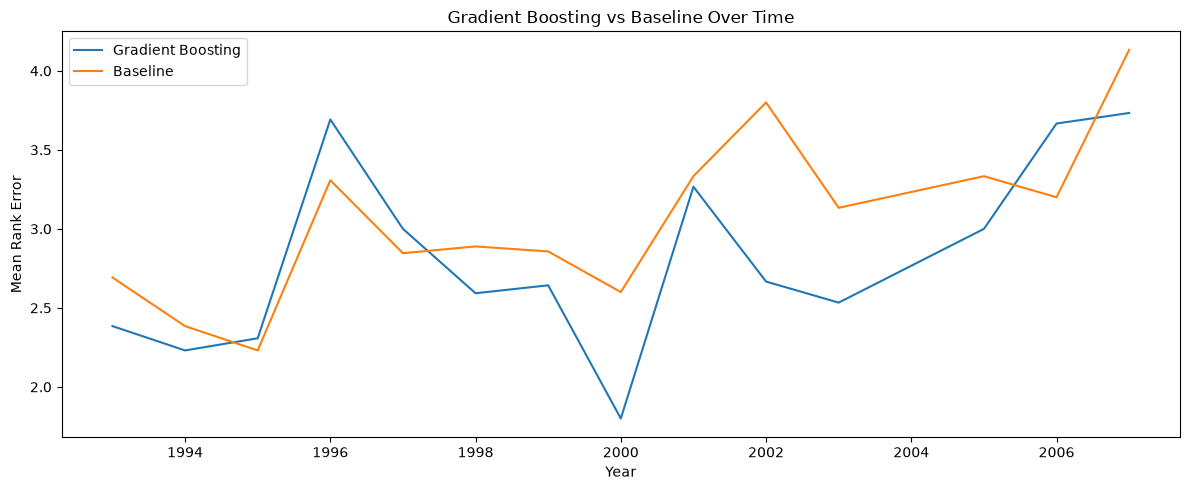

In [437]:

# Best model historical performance
best_model_history = (
    all_results[
        all_results["Model"] == best_model
    ][["Year", "Mean Rank Error"]]
    .rename(columns={
        "Mean Rank Error": best_model
    })
)

# Historical baseline performance
baseline_history = pd.DataFrame([
    {
        "Year": year,
        "Baseline": evaluate_baseline(
            df[df["year"] == year]
        )["rank_error"].mean()
    }
    for year in sorted(all_results["Year"].unique())
])

# Combine model and baseline results
comparison_history = best_model_history.merge(
    baseline_history,
    on="Year",
    how="inner"
)

# Average historical performance
display(
    comparison_history[
        [best_model, "Baseline"]
    ].mean().to_frame("Mean Rank Error")
)

# Plot historical performance
comparison_history.plot(
    x="Year",
    y=[best_model, "Baseline"],
    kind="line",
    figsize=(12, 5)
)

plt.ylabel("Mean Rank Error")
plt.title(f"{best_model} vs Baseline Over Time")
plt.tight_layout()
plt.show()


### Statistical Comparison Against the Baseline

A paired statistical comparison is performed to assess
whether the selected model significantly improves
over the baseline across historical seasons.

In [438]:
# Paired statistical comparison against the baseline
baseline_diff = (
    comparison_history["Baseline"] -
    comparison_history[best_model]
)

t_stat, p_val_t = ttest_rel(
    comparison_history["Baseline"],
    comparison_history[best_model]
)

if np.allclose(baseline_diff, 0):
    p_val_w = 1.0
else:
    w_stat, p_val_w = wilcoxon(baseline_diff)

print(f"Mean improvement: {baseline_diff.mean():.4f}")
print(f"Paired T-Test p-value: {p_val_t:.4f}")
print(f"Wilcoxon p-value: {p_val_w:.4f}")

print(
    f"Seasons outperforming baseline: "
    f"{(baseline_diff > 0).sum()}/{len(baseline_diff)}"
)

Mean improvement: 0.2302
Paired T-Test p-value: 0.0695
Wilcoxon p-value: 0.0900
Seasons outperforming baseline: 10/14


## Model Comparison for Selected Season

The regression models are trained using historical data
and evaluated on the selected target season.

Predicted performance is converted into conference
rankings using the applicable division-specific rules.

In [439]:
results = []
predictions = {}

for name, model in tuned_models.items():

    # Train model
    model.fit(X_train, y_train)

    # Predict target season
    pred_test = model.predict(X_test)

    predictions[name] = pred_test

    # Regression metrics
    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            pred_test
        )
    )

    r2 = r2_score(
        y_test,
        pred_test
    )

    # Convert predicted performance into regular-season ranking
    temp = test[
        [
            "lgID",
            "year",
            "tmID",
            "confID",
            "divID",
            "target_rank"
        ]
    ].copy()

    temp["predicted_performance"] = pred_test

    temp["predicted_rank"] = calculate_ranking(
        temp,
        score_col="predicted_performance"
    )

    # Mean absolute ranking error
    rank_error = (temp["target_rank"] - temp["predicted_rank"]).abs().mean()

    results.append({
        "Model": name,
        "RMSE": rmse,
        "R2": r2,
        "Mean Rank Error": rank_error
    })

In [440]:
results_df = pd.DataFrame(results)

results_df.sort_values("Mean Rank Error")

,Model,RMSE,R2,Mean Rank Error
0,Gradient Boosting,0.846052,0.259513,3.466667
1,Random Forest,0.829401,0.288373,3.466667
3,KNN Regressor,0.844154,0.262833,3.466667
2,Linear Regression,0.869491,0.217915,3.666667


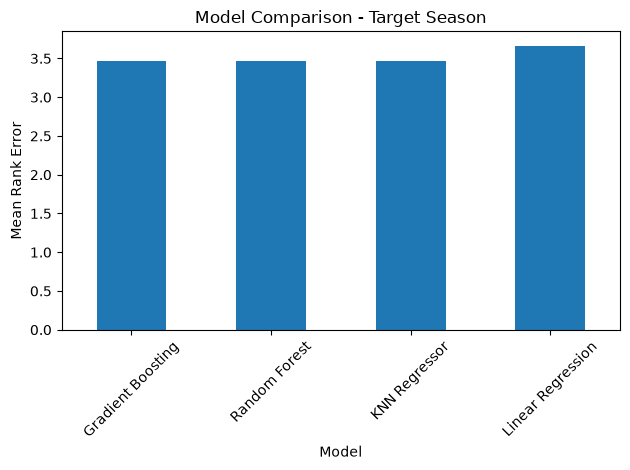

In [441]:
results_df.sort_values(
    "Mean Rank Error"
).plot(
    x="Model",
    y="Mean Rank Error",
    kind="bar",
    legend=False
)

plt.ylabel("Mean Rank Error")
plt.title("Model Comparison - Target Season")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [442]:
baseline = evaluate_baseline(
    df[df["year"] == TARGET_YEAR]
)

baseline_mean_rank_error = baseline["rank_error"].mean()

print(f"Baseline Mean Rank Error: {baseline_mean_rank_error:.3f}")

Baseline Mean Rank Error: 3.133


## Train vs Test Performance & Algorithm Behavior

Training and test RMSE are compared to evaluate generalization and understand the behavior of the four algorithm families in this domain:

- **Linear Regression:** Assumes a global linear relationship between past and future Z-scores. Because team strength in the NHL tends to regress toward the mean, a constrained linear model avoids fitting seasonal noise and generalizes with minimal gap between Train and Test RMSE.

- **KNN Regressor:** Predicts performance by averaging the 5 most similar historical team seasons. It shows moderate overfitting on training data and struggles slightly more in test seasons when a team's feature combination is atypical.

- **Random Forest:** Builds deep, unpruned decision trees by default. It memorizes specific historical team-season combinations (high variance/overfitting), though ensemble averaging still keeps its test ranking competitive.

- **Gradient Boosting:** Sequentially fits trees to residuals. While less overfitted on the training set than Random Forest, sequential boosting on noisy sports data can over-adjust to historical outliers, reducing out-of-sample generalization.

In [443]:
overfitting_results = []

for name, model in tuned_models.items():

    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)

    train_rmse = np.sqrt(
        mean_squared_error(
            y_train,
            pred_train
        )
    )

    test_rmse = np.sqrt(
        mean_squared_error(
            y_test,
            pred_test
        )
    )

    overfitting_results.append({
        "Model": name,
        "Train RMSE": train_rmse,
        "Test RMSE": test_rmse
    })

overfitting_df = pd.DataFrame(overfitting_results)

overfitting_df

,Model,Train RMSE,Test RMSE
0,Gradient Boosting,0.700758,0.846052
1,Random Forest,0.726287,0.829401
2,Linear Regression,0.752048,0.869491
3,KNN Regressor,0.713904,0.844154


## Linear Regression Coefficients

Since Linear Regression is an interpretable ("white-box") model, its coefficients can be inspected directly. Because all input features were standardized using within-season Z-scores, the coefficient magnitudes are on a comparable scale and directly reflect each feature's relative importance.

In [444]:
linear_model = tuned_models["Linear Regression"]

coefficients_df = pd.DataFrame({
    "Feature": features,
    "Coefficient": linear_model.coef_
})

coefficients_df["Absolute Coefficient"] = (coefficients_df["Coefficient"].abs())
coefficients_df = coefficients_df.sort_values("Absolute Coefficient", ascending = False)

coefficients_df

,Feature,Coefficient,Absolute Coefficient
0,prev_league_pts_per_game,1.649442,1.649442
4,pts_momentum,-1.154421,1.154421
3,prev_2y_league_pts_per_game,-0.965261,0.965261
2,prev_num_coaches,0.099984,0.099984
1,prev_player_pts_per_game,0.031326,0.031326


## Selected Season Ranking

The model with the lowest average ranking error across
historical validation seasons is selected.

The selected model is used to predict the regular-season
rankings for the target season.

Predicted rankings are compared with reconstructed actual
rankings to identify prediction errors.

In [445]:

# Select best model for the selected development season
best_model_name = best_model

test_results = test[
    [
        "year",
        "lgID",
        "tmID",
        "name",
        "confID",
        "divID",
        "target_rank"
    ]
].copy()

test_results["predicted_performance"] = predictions[best_model_name]

# Calculate predicted regular-season ranking
test_results["predicted_rank"] = calculate_ranking(
    test_results,
    score_col="predicted_performance"
)

# Calculate individual team ranking errors
test_results["rank_error"] = (
    test_results["target_rank"] -
    test_results["predicted_rank"]
).abs()

print(f"Best model: {best_model_name}")

display(
    test_results.sort_values(
        ["confID", "predicted_rank"]
    )
)


Best model: Gradient Boosting


,year,lgID,tmID,name,confID,divID,target_rank,predicted_performance,predicted_rank,rank_error
873,2008,NHL,OTT,Ottawa Senators,EC,NE,11,0.728276,1,10
993,2008,NHL,PIT,Pittsburgh Penguins,EC,AT,4,0.650209,2,2
1253,2008,NHL,WAS,Washington Capitals,EC,SE,2,-0.017377,3,1
736,2008,NHL,NJD,New Jersey Devils,EC,AT,3,0.569339,4,1
161,2008,NHL,BUF,Buffalo Sabres,EC,NE,10,0.494605,5,5
675,2008,NHL,MTL,Montreal Canadiens,EC,NE,8,0.318899,6,2
915,2008,NHL,PHI,Philadelphia Flyers,EC,AT,5,0.039117,7,2
856,2008,NHL,NYR,New York Rangers,EC,AT,7,0.007162,8,1
228,2008,NHL,CAR,Carolina Hurricanes,EC,SE,6,-0.034218,9,3
122,2008,NHL,BOS,Boston Bruins,EC,NE,1,-0.047717,10,9



## Final Model Selection & Statistical Analysis

- **Hyperparameter Tuning:** Systematic hyperparameter search improved KNN, Random Forest and Gradient Boosting, while Linear Regression remained unchanged.

- **Predictive Performance:** Gradient Boosting achieved the lowest validation Mean Rank Error (2.8227), the lowest RMSE (0.7756), and the highest R² (0.3680).

- **Baseline Comparison:** Gradient Boosting improved the average validation Mean Rank Error by approximately 7.54%, from 3.0529 to 2.8227, outperforming the baseline in 10 out of 14 seasons.

- **Statistical Significance:** There is insufficient evidence of significant differences between the optimized models or between Gradient Boosting and the baseline (Paired T-Test p = 0.0695; Wilcoxon p = 0.0900). These comparisons are exploratory because the same seasons were used for hyperparameter selection.

- **Overfitting Analysis:** Gradient Boosting presented the largest generalization gap, with a training RMSE of 0.7008 and a test RMSE of 0.8461, suggesting potential overfitting.

- **Final Model Selection:** Gradient Boosting was selected based on its historical validation performance.

- **Target Season Performance:** Gradient Boosting achieved a Mean Rank Error of 3.4667 in 2008, compared to 3.1333 for the baseline.

- **Limitations:** Historical ranking reconstruction uses approximate tie-breaking criteria. Improvements observed during hyperparameter tuning do not necessarily generalize to future seasons

## Summary of Feature Engineering and Selection Experiments

Our final modelling pipeline was guided by iterative performance improvements across historical validation splits:

- **Domain Ratios & Within-Season Z-Scores:** Converting raw totals into per-game ratios and standardizing within each season (within_season_z) was essential to make different NHL eras comparable.

- **Automated Filter + Wrapper Pipeline:** Applying a Pearson correlation filter (r > 0.85) on the training set systematically removed collinear redundant variables, while RFE consistently retained the top 5 most informative predictors for each era.

- **Discarded Features:** TeamVsTeam features and penalty minutes were tested in earlier iterations but increased historical ranking error due to noise, so they were excluded from base_features.

- **Retained Domain Predictors:** Combining 1year and 2year historical performance, recent trajectory, roster scoring depth, goaltending, and coaching stability provided the most robust ranking predictions.